# Question 2: Patient Disease Diagnosis Prediction
**Task:** Supervised Machine Learning – Binary Classification  
**Target Variable:** `diagnosis` (0 = Healthy, 1 = Disease Present)  
**Input Features:** `age`, `blood_pressure`, `glucose_level`, `cholesterol_level`  

### Marks Rubric (40 Marks):
1. **Section 1: EDA [10 Marks]** — Dataset creation, inspection, and class distribution
2. **Section 2: Technique Implementation [10 Marks]** — Preprocessing & Baseline Logistic Regression
3. **Section 3: Evaluate Model [10 Marks]** — Confusion Matrix, Accuracy, Precision, Recall, F1-Score
4. **Section 4: Modify Technique Based on Requirement [10 Marks]** — Decision Tree / Random Forest Classifier with Hyperparameter Tuning (GridSearchCV)

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

plt.rcParams['figure.figsize'] = (8, 4)
print("Libraries imported successfully!")

Libraries imported successfully!


## Section 1: Exploratory Data Analysis (EDA) [10 Marks]

In [2]:
# 1.1 Simple Exam-Friendly Dataset Generation (500 samples)
np.random.seed(42)
n = 500

age = np.random.randint(25, 75, n)
blood_pressure = np.random.uniform(90, 180, n)
glucose_level = np.random.uniform(70, 220, n)
cholesterol_level = np.random.uniform(140, 320, n)

# Simple score threshold for binary target
score = 0.04 * age + 0.02 * blood_pressure + 0.03 * glucose_level + 0.015 * cholesterol_level - 10.0
prob = 1 / (1 + np.exp(-score))
diagnosis = (prob > 0.50).astype(int)

df = pd.DataFrame({
    'age': age,
    'blood_pressure': np.round(blood_pressure, 1),
    'glucose_level': np.round(glucose_level, 1),
    'cholesterol_level': np.round(cholesterol_level, 1),
    'diagnosis': diagnosis
})

print("Dataset created! Shape:", df.shape)
df.head()

Dataset created! Shape: (500, 5)


,age,blood_pressure,glucose_level,cholesterol_level,diagnosis
0,63,134.2,72.0,186.4,1
1,53,132.6,169.5,223.3,1
2,39,105.6,96.7,296.3,1
3,67,129.0,214.2,270.9,1
4,32,125.9,92.3,273.7,1


In [3]:
# 1.2 Inspection & Class Balance Check
print("=== Dataset Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Target Class Distribution ===")
print(df['diagnosis'].value_counts())

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                500 non-null    int64  
 1   blood_pressure     500 non-null    float64
 2   glucose_level      500 non-null    float64
 3   cholesterol_level  500 non-null    float64
 4   diagnosis          500 non-null    int64  
dtypes: float64(3), int64(2)
memory usage: 19.7 KB

=== Missing Values ===
age                  0
blood_pressure       0
glucose_level        0
cholesterol_level    0
diagnosis            0
dtype: int64

=== Target Class Distribution ===
diagnosis
1    465
0     35
Name: count, dtype: int64


/var/folders/hm/g9cgxswn4jd9nz_kd3zhpr100000gn/T/ipykernel_23309/1940614788.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diagnosis', data=df, ax=axes[0], palette=['lightgreen', 'salmon'])
/var/folders/hm/g9cgxswn4jd9nz_kd3zhpr100000gn/T/ipykernel_23309/1940614788.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Healthy (0)', 'Disease (1)'])
/var/folders/hm/g9cgxswn4jd9nz_kd3zhpr100000gn/T/ipykernel_23309/1940614788.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='diagnosis', y='glucose_level', data=df, ax=axes[1], palette=['

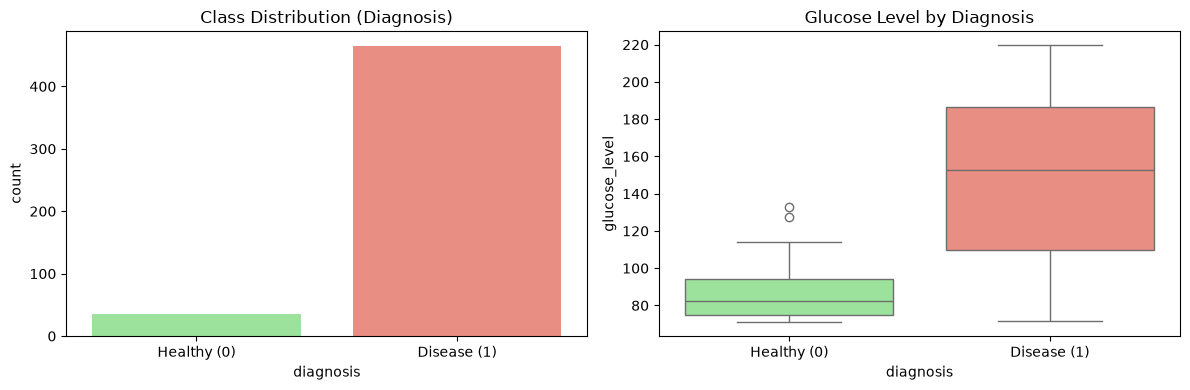

In [4]:
# 1.3 EDA Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Target Class Count
sns.countplot(x='diagnosis', data=df, ax=axes[0], palette=['lightgreen', 'salmon'])
axes[0].set_xticklabels(['Healthy (0)', 'Disease (1)'])
axes[0].set_title("Class Distribution (Diagnosis)")

# Glucose Level by Diagnosis
sns.boxplot(x='diagnosis', y='glucose_level', data=df, ax=axes[1], palette=['lightgreen', 'salmon'])
axes[1].set_xticklabels(['Healthy (0)', 'Disease (1)'])
axes[1].set_title("Glucose Level by Diagnosis")

plt.tight_layout()
plt.show()

## Section 2: Supervised Technique Implementation [10 Marks]

In [5]:
# 2.1 Feature-Target Split and Stratified Train-Test Split (80-20)
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (400, 4), X_test: (100, 4)


In [6]:
# 2.2 Baseline Model: Logistic Regression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)
print("Baseline Logistic Regression trained successfully!")

Baseline Logistic Regression trained successfully!


## Section 3: Model Evaluation [10 Marks]

,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline Logistic Regression,0.97,0.9688,1.0,0.9841


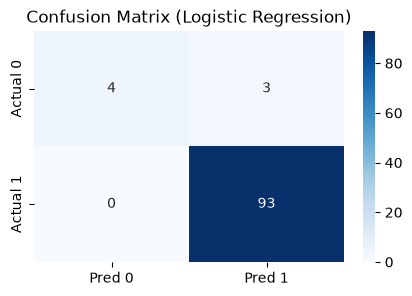


Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.57      0.73         7
           1       0.97      1.00      0.98        93

    accuracy                           0.97       100
   macro avg       0.98      0.79      0.86       100
weighted avg       0.97      0.97      0.97       100



In [7]:
# 3.1 Quantitative Metrics & Confusion Matrix
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

results_lr = {
    'Model': 'Baseline Logistic Regression',
    'Accuracy': round(acc_lr, 4),
    'Precision': round(prec_lr, 4),
    'Recall': round(rec_lr, 4),
    'F1-Score': round(f1_lr, 4)
}
display(pd.DataFrame([results_lr]))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(5, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title("Confusion Matrix (Logistic Regression)")
plt.show()

print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

## Section 4: Modify Technique Based on Requirement [10 Marks]
**Modifications Applied (from Lab 8 & Lab 10):**
1. **Advanced Model:** `RandomForestClassifier` to capture non-linear interactions between risk factors.
2. **Hyperparameter Tuning:** `GridSearchCV` on `n_estimators` and `max_depth`.
3. **Feature Importance:** Determining which medical feature has the highest diagnostic impact.

In [8]:
# 4.1 Hyperparameter Tuning: Random Forest Classifier (GridSearchCV)
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 8]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='f1')
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test)

results_rf = {
    'Model': f"Tuned Random Forest {grid_rf.best_params_}",
    'Accuracy': round(accuracy_score(y_test, y_pred_rf), 4),
    'Precision': round(precision_score(y_test, y_pred_rf), 4),
    'Recall': round(recall_score(y_test, y_pred_rf), 4),
    'F1-Score': round(f1_score(y_test, y_pred_rf), 4)
}

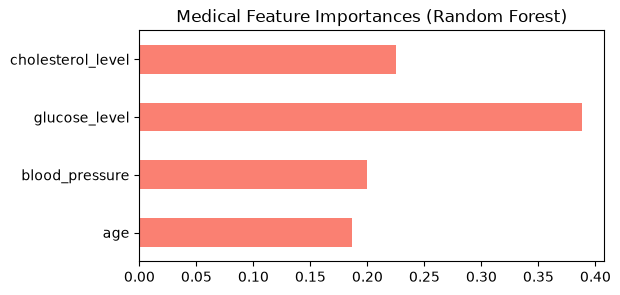

=== Final Model Comparison Table ===


,Model,Accuracy,Precision,Recall,F1-Score
0,Baseline Logistic Regression,0.97,0.9688,1.0,0.9841
1,"Tuned Random Forest {'max_depth': 5, 'n_estima...",0.96,0.9588,1.0,0.9789


In [9]:
# 4.2 Feature Importance & Comparison Table
fig, ax = plt.subplots(figsize=(6, 3))
feat_importances = pd.Series(best_rf.feature_importances_, index=X.columns)
feat_importances.plot(kind='barh', color='salmon', ax=ax)
ax.set_title("Medical Feature Importances (Random Forest)")
plt.show()

comparison_df = pd.DataFrame([results_lr, results_rf])
print("=== Final Model Comparison Table ===")
display(comparison_df)